<a href="https://colab.research.google.com/github/scribenaz/CPP528/blob/main/Exercise_17_ex_8_2_cars.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Shriver Smith  
Exercise 8-2 Analyze the Cars data  
Class: AIM111 - Introduction to Data Science  
Date: October 27, 2026

# Exercise 8-2: Analyze the Cars data

## Import the data

In [1]:
import pandas as pd
import seaborn as sns

In [2]:
cars = pd.read_pickle('cars.pkl')

In [ ]:
# display the first five rows

In [3]:
cars.head()

,aspiration,carbody,enginesize,curbweight,price
0,std,convertible,130,2548,13495.0
1,std,convertible,130,2548,16500.0
2,std,hatchback,152,2823,16500.0
3,std,sedan,109,2337,13950.0
4,std,sedan,136,2824,17450.0


## Melt the data

In [ ]:
# melt the enginesize and curbweight columns

In [5]:
cars_melted = cars.melt(
    id_vars='price',
    value_vars=['enginesize','curbweight'],
    var_name='feature',
    value_name='value'
)

In [8]:
cars_melted.head()

,price,feature,value
0,13495.0,enginesize,130
1,16500.0,enginesize,130
2,16500.0,enginesize,152
3,13950.0,enginesize,109
4,17450.0,enginesize,136


In [ ]:
# create a scatterplot for the melted data

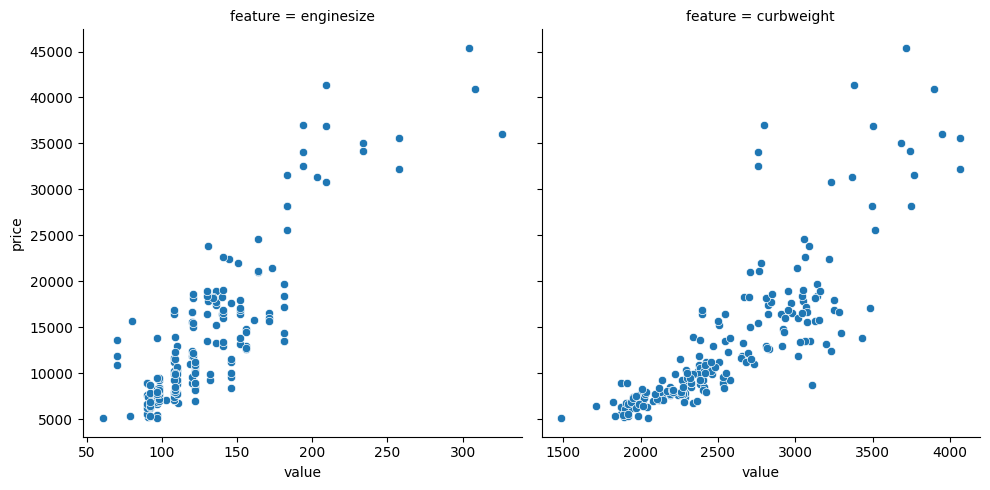

In [9]:
sns.relplot(data=cars_melted, kind='scatter', x='value', y='price', col='feature', facet_kws={'sharex':False})

## Rank the data by price

In [ ]:
# add a priceRank column that ranks each row by the price value

In [10]:
cars['priceRank'] = cars.price.rank()

In [ ]:
# display the ten rows with the lowest price in ascending order from lowest price to highest

In [11]:
cars.sort_values('price').head(10)

,aspiration,carbody,enginesize,curbweight,price,priceRank
138,std,hatchback,97,2050,5118.0,1.0
18,std,hatchback,61,1488,5151.0,2.0
50,std,hatchback,91,1890,5195.0,3.0
150,std,hatchback,92,1985,5348.0,4.0
76,std,hatchback,92,1918,5389.0,5.0
32,std,hatchback,79,1837,5399.0,6.0
89,std,sedan,97,1889,5499.0,7.0
118,std,hatchback,90,1918,5572.0,8.5
21,std,hatchback,90,1876,5572.0,8.5
51,std,hatchback,91,1900,6095.0,10.0


## Bin the data with quantiles

In [ ]:
# use the qcut() method to create three price bins for the data: low, medium, and high
# store these bins in a new column named priceGrade

In [12]:
cars['priceGrade'] = pd.qcut(cars.price, q=3, labels=['low','medium','high'])

In [ ]:
# display the number of values for each bin in the priceGrade column

In [13]:
cars.priceGrade.value_counts()

,count
priceGrade,
medium,69
low,68
high,68


## Group and aggregate the data

In [ ]:
# group the cars data by the priceGrade column and display the min and max price for each group

In [17]:
price_grouped = cars.groupby(['priceGrade']).price.agg(['min','max'])
price_grouped

/tmp/ipykernel_1557/3986115257.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  price_grouped = cars.groupby(['priceGrade']).price.agg(['min','max'])


,min,max
priceGrade,,
low,5118.0,8358.0
medium,8449.0,13860.0
high,13950.0,45400.0


In [ ]:
# group the data by the carbody and aspiration columns and get the average price for each group

In [18]:
body_and_aspiration_grouped = cars.groupby(['carbody','aspiration']).price.mean()
body_and_aspiration_grouped

carbody      aspiration
convertible  std           21890.500000
hardtop      std           21356.000000
             turbo         28176.000000
hatchback    std            9699.605263
             turbo         13345.243615
sedan        std           13660.371795
             turbo         17307.833333
wagon        std           10973.600000
             turbo         17965.400000
Name: price, dtype: float64

In [ ]:
# unstack the aspiration column of the index

In [19]:
body_and_aspiration_grouped = body_and_aspiration_grouped.unstack()
body_and_aspiration_grouped

aspiration,std,turbo
carbody,,
convertible,21890.500000,NaN
hardtop,21356.000000,28176.000000
hatchback,9699.605263,13345.243615
sedan,13660.371795,17307.833333
wagon,10973.600000,17965.400000


In [ ]:
# use the pivot_table() method to accomplish the same task as the previous cell

In [20]:
cars.pivot_table(index='carbody', columns='aspiration', values='price')

aspiration,std,turbo
carbody,,
convertible,21890.500000,NaN
hardtop,21356.000000,28176.000000
hatchback,9699.605263,13345.243615
sedan,13660.371795,17307.833333
wagon,10973.600000,17965.400000


In [ ]:
# use the Pandas plot() method to create a bar chart for the DataFrame created in the previous cell

<Axes: title={'center': 'Average Price by Body Type and Aspiration'}, xlabel='carbody', ylabel='average price'>

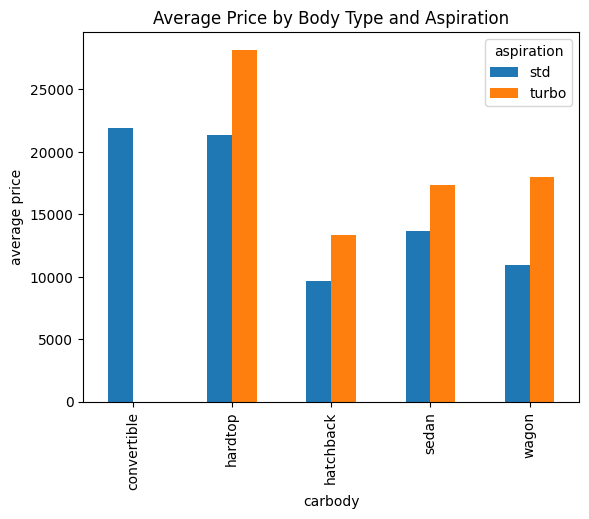

In [23]:
cars.pivot_table(index='carbody', columns='aspiration', values='price').plot(kind='bar',ylabel='average price', title='Average Price by Body Type and Aspiration')